In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

TEMPDIR = Path(config['TEMPDIR'])
import pysam
from typing import Tuple
import re
import pyranges as pr

# Annotation

## Splice junctions

In [ ]:
def sam_to_dataframe(sam_path, max_reads=None):
    aln_file = pysam.AlignmentFile(sam_path, "r")

    rows = []
    for i, read in enumerate(aln_file.fetch(until_eof=True)):
        row = {
            "qname": read.query_name,
            "flag": read.flag,
            "chrom": read.reference_name,
            "pos": read.reference_start + 1,  # make 1-based
            "strand": "-" if read.is_reverse else "+",
            "cigar": read.cigarstring,
            "mapq": read.mapping_quality,
            "seq": read.query_sequence,
            "nm": read.get_tag("NM") if read.has_tag("NM") else None,
            "nh": read.get_tag("NH") if read.has_tag("NH") else None,
            "as": read.get_tag("AS") if read.has_tag("AS") else None,
        }
        rows.append(row)
        if max_reads and i >= max_reads:
            break

    return pd.DataFrame(rows)

def is_spliced(cigar: str) -> bool:
    return "N" in cigar if cigar else False

samfile_df = sam_to_dataframe(TEMPDIR / "hisat2/guides_aligned_v48_genome_spliceaware.sam", max_reads=10000000)
samfile_df["is_spliced"] = samfile_df["cigar"].apply(is_spliced)
samfile_df["multiple"] = samfile_df.duplicated(subset=["qname"], keep=False)

def classify_splice_junction(cigar: str, chrom: str, start_pos: int, strand: str, exons: pr.PyRanges) -> str:
    """
    Classifies a spliced alignment given a CIGAR string and position info.

    Parameters:
        cigar: str         → CIGAR string (e.g. "12M100N11M")
        chrom: str         → Chromosome (e.g. "chr12")
        start_pos: int     → 0-based genomic start position of alignment
        strand: str        → "+" or "-" strand
        exons: PyRanges    → Exon annotation (filtered GTF)

    Returns:
        str: ASCII-safe label:
            - "Exon -> Intron"
            - "Intron -> Exon"
            - "Exon -> Exon"
            - "Ambiguous" or "Not junctional"
    """
    # Parse CIGAR string
    ops = re.findall(r"(\d+)([A-Z=])", cigar)
    ops = [(int(length), op) for length, op in ops]

    # Look for spliced alignment
    splice_indices = [i for i, (_, op) in enumerate(ops) if op == "N"]
    if not splice_indices:
        return "Not junctional"

    splice_idx = splice_indices[0]

    # Build list of aligned reference blocks (M/D/N consume ref)
    blocks = []
    pos = start_pos
    for length, op in ops:
        if op in {"M", "D", "N"}:
            end = pos + length
            blocks.append((pos, end))
            pos = end
        elif op in {"I", "S", "H"}:
            continue  # doesn't consume reference

    if len(blocks) < 2:
        return "Ambiguous"

    try:
        block1 = blocks[splice_idx - 1]
        block2 = blocks[splice_idx]
    except IndexError:
        return "Ambiguous"

    # Helper to check overlap with exon annotation
    def block_label(block: Tuple[int, int]) -> str:
        block_df = pd.DataFrame({
            "Chromosome": [chrom],
            "Start": [block[0]],
            "End": [block[1]]
        })
        pr_block = pr.PyRanges(block_df)
        return "Exon" if len(pr_block.overlap(exons)) > 0 else "Intron"

    label1 = block_label(block1)
    label2 = block_label(block2)

    # Return strand-aware direction
    if strand == "+":
        return f"{label1} -> {label2}"
    elif strand == "-":
        return f"{label2} <- {label1}"
    else:
        return "Ambiguous"


# This takes some time to run
gtf = pr.read_gtf(TEMPDIR / "hisat2/gencode.v48.annotation.gtf")
exons = gtf[gtf.Feature == "exon"]

tqdm.pandas()
samfile_df["splice_junction"] = samfile_df.progress_apply(
    lambda row: classify_splice_junction(
        cigar=row["cigar"],
        chrom=row["chrom"],
        start_pos=row["pos"],
        strand=row["strand"],
        exons=exons
    ) if row["is_spliced"] else "Not junctional",
    axis=1
)
tqdm.pandas(disable=True)
samfile_df.to_csv("../results/tables/guide_splice_junctions.csv", index=False)

## Genes

In [65]:
samfile_df = pd.read_csv("../results/tables/guide_splice_junctions.csv")

In [67]:
# This takes some time to run
gtf = pr.read_gtf(TEMPDIR / "hisat2/gencode.v48.annotation.gtf")
genes = gtf[gtf.Feature == "gene"]

In [76]:
def extract_blocks_from_row(row):
    cigar = row["cigar"]
    chrom = row["chrom"]
    strand = row["strand"]
    pos = row["pos"]  # 1-based SAM, convert to 0-based for PyRanges

    if not isinstance(cigar, str) or pd.isna(cigar):
        return []  # skip invalid rows

    ops = re.findall(r"(\d+)([A-Z=])", cigar)
    ops = [(int(length), op) for length, op in ops]

    blocks = []
    ref_pos = pos - 1
    for length, op in ops:
        if op in {"M", "D", "N"}:
            end = ref_pos + length
            blocks.append({
                "Chromosome": chrom,
                "Start": ref_pos,
                "End": end,
                "qname": row["qname"],
                "strand": strand
            })
            ref_pos = end
        elif op in {"I", "S", "H"}:
            continue  # doesn't consume reference

    return blocks


In [77]:
# Turn aligned blocks into a PyRanges
all_blocks = []
for _, row in tqdm(samfile_df.iterrows(), total=len(samfile_df)):
    all_blocks.extend(extract_blocks_from_row(row))
blocks_df = pd.DataFrame(all_blocks)
blocks_gr = pr.PyRanges(blocks_df)

  0%|          | 0/8937 [00:00<?, ?it/s]

In [78]:
# Intersect with genes and annotate
annotated = blocks_gr.join(genes, strandedness=False)

join: Strand data from other will be added as strand data to self.
If this is undesired use the flag apply_strand_suffix=False.
To turn off the warning set apply_strand_suffix to True or False.


In [81]:
# Get qname to gene_name mapping
gene_map = annotated.df.groupby("qname")["gene_name"].unique().apply(lambda x: ";".join(sorted(set(x))))
samfile_df["alignment_on_gene"] = samfile_df["qname"].map(gene_map)

In [83]:
samfile_df['guide_target'] = samfile_df['qname'].str.split('_').str[0]

In [94]:
samfile_df['alignment_and_target_differ'] = samfile_df['alignment_on_gene'] != samfile_df['guide_target']
samfile_df['target_in_alignments'] = [str(y) in str(x) for x, y in zip(samfile_df['alignment_on_gene'], samfile_df['guide_target'])]

In [87]:
samfile_df[samfile_df.alignment_and_target_differ]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ
5,PHF5A_ENST00000216252_825,0,chr2,168231503,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
6,PHF5A_ENST00000216252_825,256,chr22,41459978,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
13,PHF5A_ENST00000216252_590,0,chr22,41460213,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
14,PHF5A_ENST00000216252_590,256,chr2,168231738,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
15,COX15_ENST00000016171_1326,0,chr10,99714545,+,23M,60,CTCAAAAGCAGTCACAGTCCCAG,0.0,1.0,0.0,False,False,Not junctional,COX15;CUTC;ENSG00000285932,COX15,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True


In [95]:
samfile_df[~samfile_df.target_in_alignments]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
266,TARS1_ENST00000265112_3747,16,chr5,33468950,-,23M,60,AAGGATGCCTTTATTGTTTCTGG,0.0,1.0,0.0,False,False,Not junctional,NaN,TARS1,True,False
492,MAP2K1_ENST00000307102_3338,16,chr15,66492218,-,23M,60,CTCCGCTCATTATTTTCTTTGAA,0.0,1.0,0.0,False,False,Not junctional,SNAPC5,MAP2K1,True,False
524,KRAS_ENST00000311936_5466,0,chr12,25205088,+,23M,60,TTTACATAATATCCACAGCACCT,0.0,1.0,0.0,False,False,Not junctional,ETFRF1,KRAS,True,False
1363,OR4A47_ENST00000446524_1044,16,chr11,48489738,-,23M,60,GGAAGAGAGTCATTTGACTTTAC,0.0,1.0,0.0,False,False,Not junctional,NaN,OR4A47,True,False
1395,OR4A47_ENST00000446524_1042,16,chr11,48489736,-,23M,60,CAGGAAGAGAGTCATTTGACTTT,0.0,1.0,0.0,False,False,Not junctional,NaN,OR4A47,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False


In [96]:
samfile_df.to_csv("../results/tables/guide_splice_junctions_genes.csv", index=False)

# Plots: Alignment stats

In [57]:
samfile_df = pd.read_csv("../results/tables/guide_splice_junctions_genes.csv")
samfile_df.head()

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True


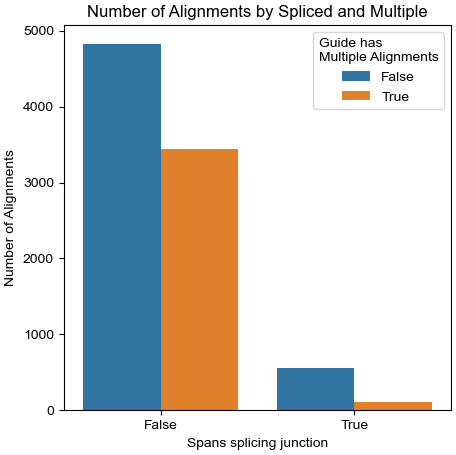

In [62]:
# Observations:
tdf = samfile_df.value_counts(["is_spliced", "multiple"]).reset_index()
fig, ax = pl.subplots(figsize=(5, 5))

sns.barplot(data=tdf, x="is_spliced", y="count", hue="multiple")
ax.set_ylabel("Number of Alignments")
ax.set_xlabel("Spans splicing junction")
ax.set_title("Number of Alignments by Spliced and Multiple")
ax.legend(title="Guide has\nMultiple Alignments", loc="upper right")
pl.show()

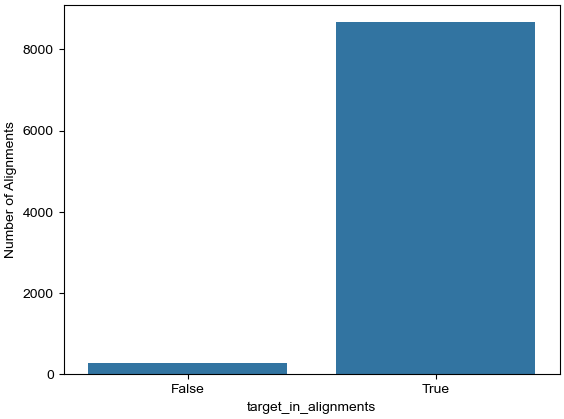

In [63]:
tdf = samfile_df.value_counts(["target_in_alignments"]).reset_index()
sns.barplot(data=tdf, y="count", x="target_in_alignments")
pl.ylabel("Number of Alignments")
pl.show()


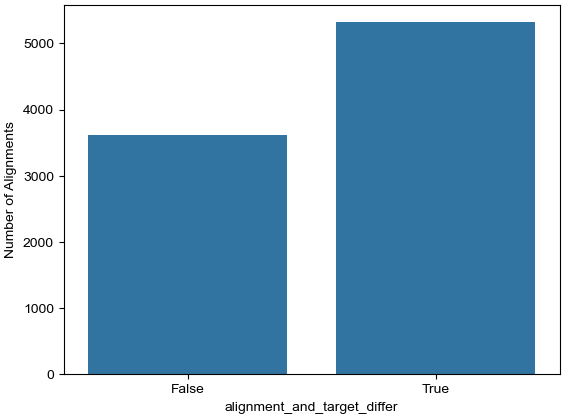

In [64]:
tdf = samfile_df.value_counts(["alignment_and_target_differ"]).reset_index()
sns.barplot(data=tdf, y="count", x="alignment_and_target_differ")
pl.ylabel("Number of Alignments")
pl.show()


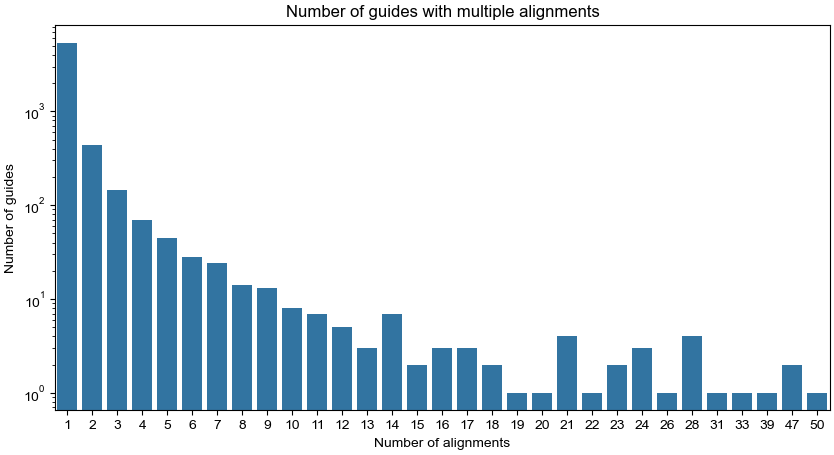

In [65]:
number_of_alignments = samfile_df.qname.value_counts().value_counts()
number_of_alignments.name = "number_of_guides"
number_of_alignments.index.name = "number_of_alignments"
number_of_alignments = number_of_alignments.reset_index()

fig, ax = pl.subplots(figsize=(10, 5))
sns.barplot(data=number_of_alignments.reset_index(), x="number_of_alignments", y="number_of_guides", ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Number of alignments")
ax.set_ylabel("Number of guides")
ax.set_title("Number of guides with multiple alignments")
pl.show()

In [66]:
samfile_df.splice_junction.value_counts()

splice_junction
Not junctional    8271
Exon <- Exon       332
Exon -> Exon       311
Exon <- Intron      13
Intron -> Exon      10
Name: count, dtype: int64

In [67]:
# Are any NT guides aligning?
samfile_df[samfile_df.qname.str.contains("NT_Control")].flag.value_counts()

flag
4    100
Name: count, dtype: int64

In [68]:
weird_NT_guides = [
    'NT_Control_rc_000138_NA',
    'NT_Control_rc_000834_NA',
    'NT_Control_rc_000481_NA',
]
# nope, they don't map at all
samfile_df[samfile_df.qname.isin(weird_NT_guides)]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
8842,NT_Control_rc_000481_NA,4,NaN,0,+,NaN,0,CGCCTGGACCAACCGAGAACATC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8911,NT_Control_rc_000138_NA,4,NaN,0,+,NaN,0,CATCCGCCCTGAATATTCACAAT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8931,NT_Control_rc_000834_NA,4,NaN,0,+,NaN,0,GATGTCGTTGAACCGATTGTTAC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False


In [69]:
samfile_df[(samfile_df.is_spliced)]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
201,RPS29_ENST00000245458_213,0,chr14,49583655,+,21M2274N2M,60,AAGGAAGAGCATTTAGTCCAACT,0.0,1.0,0.0,True,False,Exon -> Exon,RPS29,RPS29,False,True
477,CENPX_ENST00000306704_254,0,chr17,82019200,+,20M73N3M,60,GATCCCTAGAAGTCCAGGAGCAG,0.0,1.0,0.0,True,False,Exon -> Exon,CENPX,CENPX,False,True
763,HNRNPD_ENST00000353341_1281,0,chr4,82354133,+,22M1149N1M,1,TTGGAAAATACTGCTTCACCACC,0.0,2.0,0.0,True,True,Exon -> Exon,HNRNPD,HNRNPD,False,True
764,HNRNPD_ENST00000353341_1281,256,chr4,82354133,+,22M740N1M,1,TTGGAAAATACTGCTTCACCACC,0.0,2.0,0.0,True,True,Exon -> Exon,HNRNPD,HNRNPD,False,True
1190,MRPL23_ENST00000397298_597,16,chr11,1956448,-,1M93N22M,60,GGTGGGCAGCTGTGGCAGAGCAG,0.0,1.0,0.0,True,False,Exon <- Exon,MRPL23,MRPL23,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8701,GAPLINC_ENST00000581442_299,272,chr18,3467202,-,2M11552N21M,1,AGGGTATGCACAGATGTGGAAAC,0.0,4.0,0.0,True,True,Exon <- Exon,GAPLINC,GAPLINC,False,True
8702,GAPLINC_ENST00000581442_299,272,chr18,3467295,-,2M11459N21M,1,AGGGTATGCACAGATGTGGAAAC,0.0,4.0,0.0,True,True,Exon <- Exon,GAPLINC,GAPLINC,False,True
8731,CDKN2B-AS1_ENST00000583719_390,16,chr9,21995158,-,4M51589N19M,60,CTAGTGTCCCTTTTGATGAGAAG,0.0,1.0,0.0,True,False,Exon <- Exon,CDKN2A;CDKN2B;CDKN2B-AS1;ENSG00000264545;ENSG0...,CDKN2B-AS1,True,True
8807,ZEB1-AS1_ENST00000607166_136,0,chr10,31318540,+,1M355N22M,1,CCTTTCCAACTCCGACAGCCCGT,0.0,2.0,0.0,True,True,Exon -> Exon,ZEB1;ZEB1-AS1,ZEB1-AS1,True,True


In [70]:
samfile_df[(samfile_df.multiple)]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
5,PHF5A_ENST00000216252_825,0,chr2,168231503,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True
6,PHF5A_ENST00000216252_825,256,chr22,41459978,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True
13,PHF5A_ENST00000216252_590,0,chr22,41460213,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True
14,PHF5A_ENST00000216252_590,256,chr2,168231738,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True
17,ST13_ENST00000216218_2059,16,chr20,22273446,-,23M,1,TCCTGATGCATTTTGACTTGTCT,0.0,3.0,0.0,False,True,Not junctional,ENSG00000225170;LINC01427;ST13,ST13,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8815,FTX_ENST00000603037_2149,272,chr20,2778827,-,23M,1,TGCTGGGTCATATTGTAATTCTG,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True
8816,FTX_ENST00000603037_2149,256,chrX,74201977,+,23M,1,CAGAATTACAATATGACCCAGCA,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True
8822,FTX_ENST00000603037_2150,0,chr2,168874340,+,23M,1,ACAGAATTACAATATGACCCAGC,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True
8823,FTX_ENST00000603037_2150,256,chrX,74201976,+,23M,1,ACAGAATTACAATATGACCCAGC,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True


In [133]:
# Summaries per guides
cts = samfile_df.value_counts(["qname", "is_spliced", "multiple", 'alignment_on_gene', 'alignment_and_target_differ', 'target_in_alignments'], dropna=False).reset_index()
assert len(cts) == len(samfile_df.qname.unique()), "Very inconvenient"
cts.drop(columns=["count"], inplace=True)
cts.to_csv("../results/tables/guide_splice_junctions_summaries.csv", index=False)

In [71]:
# Find genes with guides that have different properties (spliced, multiple)
samfile_df['target'] = samfile_df.qname.str.split("_").str[0]
n_different_guides = samfile_df.value_counts(["target", "is_spliced", "multiple"], dropna=False, sort=False).reset_index().value_counts('target')

In [72]:
n_different_guides

target
HMGN3      4
RPL41      4
ZFAND6     4
GAS5       4
HNRNPD     4
          ..
MGAT2      1
MFAP3      1
METTL18    1
METTL14    1
ZSWIM3     1
Name: count, Length: 734, dtype: int64

In [73]:
# Are sym10x1 guides affected?

In [74]:
samfile_df

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments,target
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True,MRPS35
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True,CYP26B1
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True,LGALS1
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True,MRPS35
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True,MYH9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,NT
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,NT
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,NT
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,NT


In [75]:
len(samfile_df.target.unique())

734

# Plots: guides and screen outcome

In [76]:
samfile_df = pd.read_csv("../results/tables/guide_splice_junctions_genes.csv")

In [77]:
samfile_df

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False


In [79]:
# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality
cell_line_colors = config['cell_line_colors']

# Load Data
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)

# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc.replace(0, np.nan))

In [81]:
# target in alignment

In [83]:
samfile_df[samfile_df.target_in_alignments]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8853,AFAP1-AS1_ENST00000608442_3741,16,chr4,7775852,-,23M,60,GGGCAACACATAAATGCTTATTT,0.0,1.0,0.0,False,False,Not junctional,AFAP1;AFAP1-AS1,AFAP1-AS1,True,True
8859,AFAP1-AS1_ENST00000608442_1165,16,chr4,7773276,-,23M,60,CTGGGCCTCAATGTTCTCATTTT,0.0,1.0,0.0,False,False,Not junctional,AFAP1;AFAP1-AS1,AFAP1-AS1,True,True
8860,ZEB1-AS1_ENST00000607166_2174,0,chr10,31316857,+,23M,60,AGGACTAAAGGGATGAAGGCAGA,0.0,1.0,0.0,False,False,Not junctional,ZEB1-AS1,ZEB1-AS1,False,True
8885,AFAP1-AS1_ENST00000608442_4117,16,chr4,7776228,-,23M,60,GGTGGCATAATGATTAAGAATAA,0.0,1.0,0.0,False,False,Not junctional,AFAP1;AFAP1-AS1,AFAP1-AS1,True,True


In [ ]:
# Annotate mean l2fc per guide
l2fc['mean_l2fc'] = l2fc.loc[:, l2fc.columns.str.contains('TP6')].mean(axis=1)
samfile_df = pd.merge(samfile_df, l2fc['mean_l2fc'], left_on='qname', right_index=True, how='left')

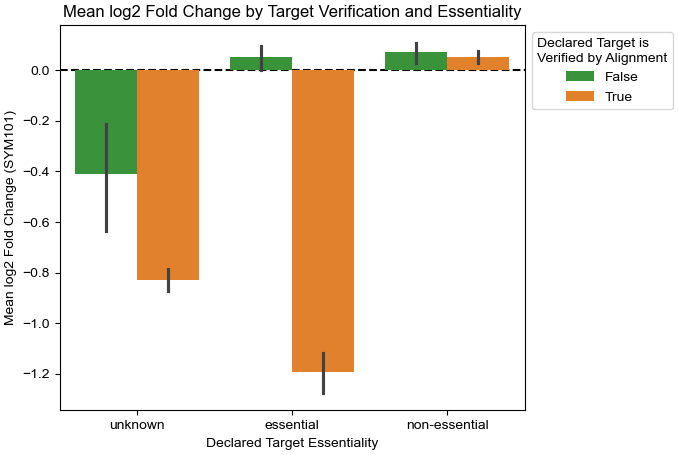

In [ ]:
# WOWOWOWOWOWOWOWOWOW
fig, ax = pl.subplots(figsize=(6, 5))
samfile_df['essentiality'] = annotate_essentiality(samfile_df['guide_target'])
sns.barplot(data=samfile_df, hue='target_in_alignments', y='mean_l2fc', ax=ax, x='essentiality', palette={True: 'tab:orange', False: 'tab:green'})
ax.legend(title='Declared Target is\nVerified by Alignment', loc='upper left', bbox_to_anchor=(1, 1))
ax.set_ylabel("Mean log2 Fold Change (SYM101)")
ax.set_xlabel("Declared Target Essentiality")
ax.axhline(0, color='black', linestyle='--', zorder=0)
ax.set_title("Mean log2 Fold Change by Target Verification and Essentiality")
pl.show()

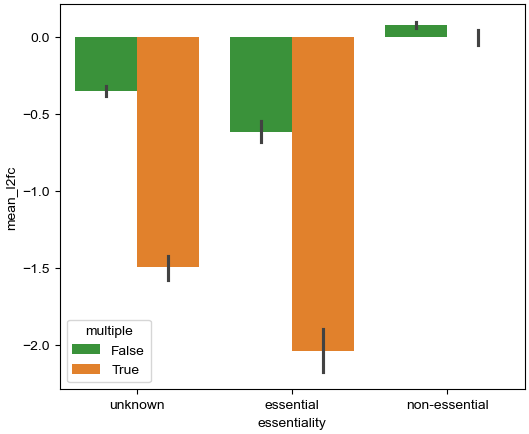

In [ ]:
# Yes well this can be mediated by gene expression...
fig, ax = pl.subplots(figsize=(6, 5))
samfile_df['essentiality'] = annotate_essentiality(samfile_df['guide_target'])
sns.barplot(data=samfile_df, hue='multiple', y='mean_l2fc', ax=ax, x='essentiality', palette={True: 'tab:orange', False: 'tab:green'})
# ax.legend(title='Declared Target is\nVerified by Alignment', loc='upper left', bbox_to_anchor=(1, 1))
# ax.set_ylabel("Mean log2 Fold Change (SYM101)")
# ax.set_xlabel("Declared Target Essentiality")
# ax.axhline(0, color='black', linestyle='--', zorder=0)
# ax.set_title("Mean log2 Fold Change by Target Verification and Essentiality")
pl.show()

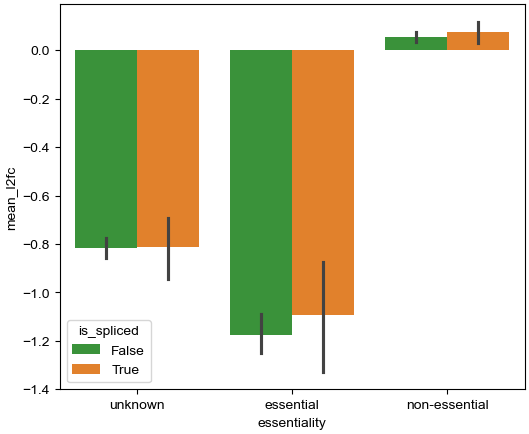

In [ ]:
# sad!
fig, ax = pl.subplots(figsize=(6, 5))
samfile_df['essentiality'] = annotate_essentiality(samfile_df['guide_target'])
sns.barplot(data=samfile_df, hue='is_spliced', y='mean_l2fc', ax=ax, x='essentiality', palette={True: 'tab:orange', False: 'tab:green'})
# ax.legend(title='Declared Target is\nVerified by Alignment', loc='upper left', bbox_to_anchor=(1, 1))
# ax.set_ylabel("Mean log2 Fold Change (SYM101)")
# ax.set_xlabel("Declared Target Essentiality")
# ax.axhline(0, color='black', linestyle='--', zorder=0)
# ax.set_title("Mean log2 Fold Change by Target Verification and Essentiality")
pl.show()

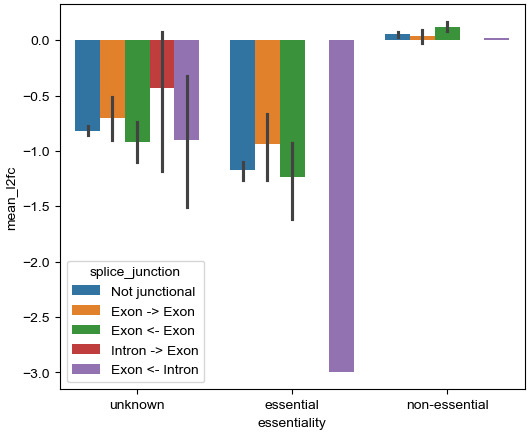

In [ ]:
# Sad?
fig, ax = pl.subplots(figsize=(6, 5))
samfile_df['essentiality'] = annotate_essentiality(samfile_df['guide_target'])
sns.barplot(data=samfile_df, hue='splice_junction', y='mean_l2fc', ax=ax, x='essentiality')#, palette={True: 'tab:orange', False: 'tab:green'})
# ax.legend(title='Declared Target is\nVerified by Alignment', loc='upper left', bbox_to_anchor=(1, 1))
# ax.set_ylabel("Mean log2 Fold Change (SYM101)")
# ax.set_xlabel("Declared Target Essentiality")
# ax.axhline(0, color='black', linestyle='--', zorder=0)
# ax.set_title("Mean log2 Fold Change by Target Verification and Essentiality")
pl.show()

# Variants x guide alignment

Do any guides align to regions where we have genomic variants?

In [84]:
samfile_df = pd.read_csv("../results/tables/guide_splice_junctions_genes.csv")
samfile_df.head()

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True


In [103]:
import pysam
from pysam import VariantFile
import pyranges as pr

samfile_df_annot = samfile_df.copy()
samfile_df_annot.set_index(['chrom', 'pos'], inplace=True)

for cell_line in tqdm(cell_line_dict.values()):

    # Get mutations
    vcf_filtered = VariantFile(TEMPDIR / f"../SYM10X1/CCLE/WGS_variants/{cell_line}_lncrna_variant_effect_output_filtered.vcf", "r")

    # vcf into pandas dataframe
    # Extract CSQ field structure from VEP header
    csq_header = vcf_filtered.header.info['CSQ'].description.split('Format: ')[1].split('|')
    records = []
    for rec in tqdm(vcf_filtered.fetch()):
        chrom = rec.chrom
        pos = rec.pos
        ref = rec.ref
        alt = ','.join(rec.alts) if rec.alts else None
        dp = rec.info.get("DP", None)
        mq = rec.info.get("MQ", None)
        dp4 = rec.info.get("DP4", (0,0,0,0))
        alt_reads = dp4[2] + dp4[3]

        csq_list = rec.info.get("CSQ", [])
        genes = set()
        consequences = set()
        impacts = set()

        for csq in csq_list:
            fields = csq.split('|')
            csq_dict = dict(zip(csq_header, fields))
            gene = csq_dict.get('SYMBOL') or csq_dict.get('Gene')
            consequence = csq_dict.get('Consequence', '')
            impact = csq_dict.get('IMPACT', '')

            if gene:
                genes.add(gene)
            if consequence:
                consequences.update(consequence.split('&'))  # can be multiple
            if impact:
                impacts.add(impact)

        records.append({
            "chrom": chrom,
            "pos": pos,
            "ref": ref,
            "alt": alt,
            "dp": dp,
            "mq": mq,
            "alt_reads": alt_reads,
            "genes": ';'.join(sorted(genes)) if genes else None,
            "consequences": ';'.join(sorted(consequences)) if consequences else None,
            "impacts": ';'.join(sorted(impacts)) if impacts else None
        })
    vcf_df = pd.DataFrame(records)
    
    # Get overlapping SNPs with guides
    variant_positions = vcf_df[['chrom', 'pos']]
    guide_positions = samfile_df[['chrom', 'pos']].dropna()  #remember length is 23 NTs
    guide_positions['end'] = guide_positions['pos'] + 23
    guide_positions.columns = ['Chromosome', 'Start', 'End']
    variant_positions['Start'] = variant_positions['pos']
    variant_positions['End'] = variant_positions['pos'] + 1
    variant_positions['Chromosome'] = variant_positions['chrom']
    
    # Convert to PyRanges objects
    snp_ranges = pr.PyRanges(variant_positions)
    guide_ranges = pr.PyRanges(guide_positions)
    # Intersect: find SNPs that fall inside guide regions
    overlaps = snp_ranges.join(guide_ranges)
    overlaps_df = overlaps.df
    
    # Add SNP info to the guide dataframe
    overlaps_df_ = overlaps_df[['chrom', 'Start_b', 'pos']]
    overlaps_df_.columns = ['chrom', 'pos', f'variant_location_{cell_line}']
    overlaps_df_.set_index(['chrom', 'pos'], inplace=True)
    samfile_df_annot = pd.merge(samfile_df_annot, overlaps_df_, left_index=True, right_index=True, how='left')

  0%|          | 0/3 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [2]:
# samfile_df_annot.reset_index().to_csv("../results/tables/guide_splice_junctions_genes_annotated.csv", index=False)
samfile_df_annot = pd.read_csv("../results/tables/guide_splice_junctions_genes_annotated.csv")

In [3]:
samfile_df_annot

,chrom,pos,qname,flag,strand,cigar,mapq,seq,nm,nh,...,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments,variant_location_H1975,variant_location_H1299,variant_location_A549
0,chr12,27755768,MRPS35_ENST00000081029_1383,16,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,...,False,False,Not junctional,MRPS35,MRPS35,False,True,NaN,NaN,NaN
1,chr2,72129262,CYP26B1_ENST00000001146_4708,0,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,...,False,False,Not junctional,CYP26B1,CYP26B1,False,True,NaN,NaN,NaN
2,chr22,37679732,LGALS1_ENST00000215909_508,16,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,...,False,False,Not junctional,LGALS1,LGALS1,False,True,NaN,NaN,NaN
3,chr12,27755987,MRPS35_ENST00000081029_1602,16,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,...,False,False,Not junctional,MRPS35,MRPS35,False,True,NaN,NaN,NaN
4,chr22,36281734,MYH9_ENST00000216181_7048,0,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,...,False,False,Not junctional,MYH9,MYH9,False,True,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9018,NaN,0,NT_Control_rc_001000_NA,4,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,...,False,False,Not junctional,NaN,NT,True,False,NaN,NaN,NaN
9019,NaN,0,NT_Control_rc_000290_NA,4,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,...,False,False,Not junctional,NaN,NT,True,False,NaN,NaN,NaN
9020,NaN,0,NT_Control_rc_000603_NA,4,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,...,False,False,Not junctional,NaN,NT,True,False,NaN,NaN,NaN
9021,NaN,0,NT_Control_rc_000800_NA,4,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,...,False,False,Not junctional,NaN,NT,True,False,NaN,NaN,NaN


In [5]:
for cell_line in cell_line_dict.values():
    n_vars = samfile_df_annot[f'variant_location_{cell_line}'].notna().sum()
    print(f"{cell_line}: {n_vars} SNPs overlapping with guides")

H1975: 128 SNPs overlapping with guides
H1299: 121 SNPs overlapping with guides
A549: 126 SNPs overlapping with guides


# Effect of genetic variants on guide efficiency

In [6]:
samfile_df_annot = pd.read_csv("../results/tables/guide_splice_junctions_genes_annotated.csv")

In [7]:
has_variant = (~samfile_df_annot[['variant_location_H1975', 'variant_location_H1299', 'variant_location_A549']].isna()).any(axis=1)

In [8]:
subdf = samfile_df_annot[has_variant]

In [9]:
# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality
cell_line_colors = config['cell_line_colors']

# Load Data
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)

# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc.replace(0, np.nan))

In [10]:
genes_with_variants = subdf.guide_target.unique()

In [11]:
# Get the foldchange for the guide targeting genes with variants in guides
# (This also grabs all the other guides that target the same gene but might not have variants)
l2fc_genes = l2fc.index.str.split("_").str[0]
l2fc_sub = l2fc[l2fc_genes.isin(genes_with_variants)]
df_sub = df[df.Gene.isin(genes_with_variants)]

In [12]:
np.sort(genes_with_variants)

array(['AATBC', 'ADAMTS9-AS2', 'ASB17', 'CACTIN', 'CASC15', 'CBR3-AS1',
       'DANCR', 'DTX2', 'EIF4A1', 'FENDRR', 'GAPDH', 'GAPLINC', 'GAS5',
       'HMGN3', 'HNF1A-AS1', 'HNRNPA1', 'HOXD9', 'HSPE1', 'IFITM3',
       'KRT86', 'LINC-PINT', 'LINC-ROR', 'LINC00974', 'LINC01139',
       'LINP1', 'LNCARSR', 'MIR31HG', 'MYCNUT', 'OVAAL', 'PCAT6', 'PCAT7',
       'PCBP2', 'PCGEM1', 'POU5F1B', 'PRELID1', 'PVT1', 'RMEL3',
       'RNASE12', 'RPL26L1', 'RPL7A', 'RPLP0', 'SYT17', 'TRMT5', 'TRPA1',
       'TRPM2-AS', 'TUBA1B', 'TUSC7', 'UBE2D3', 'UCA1', 'WT1-AS', 'XKR8'],
      dtype=object)

KeyboardInterrupt: 

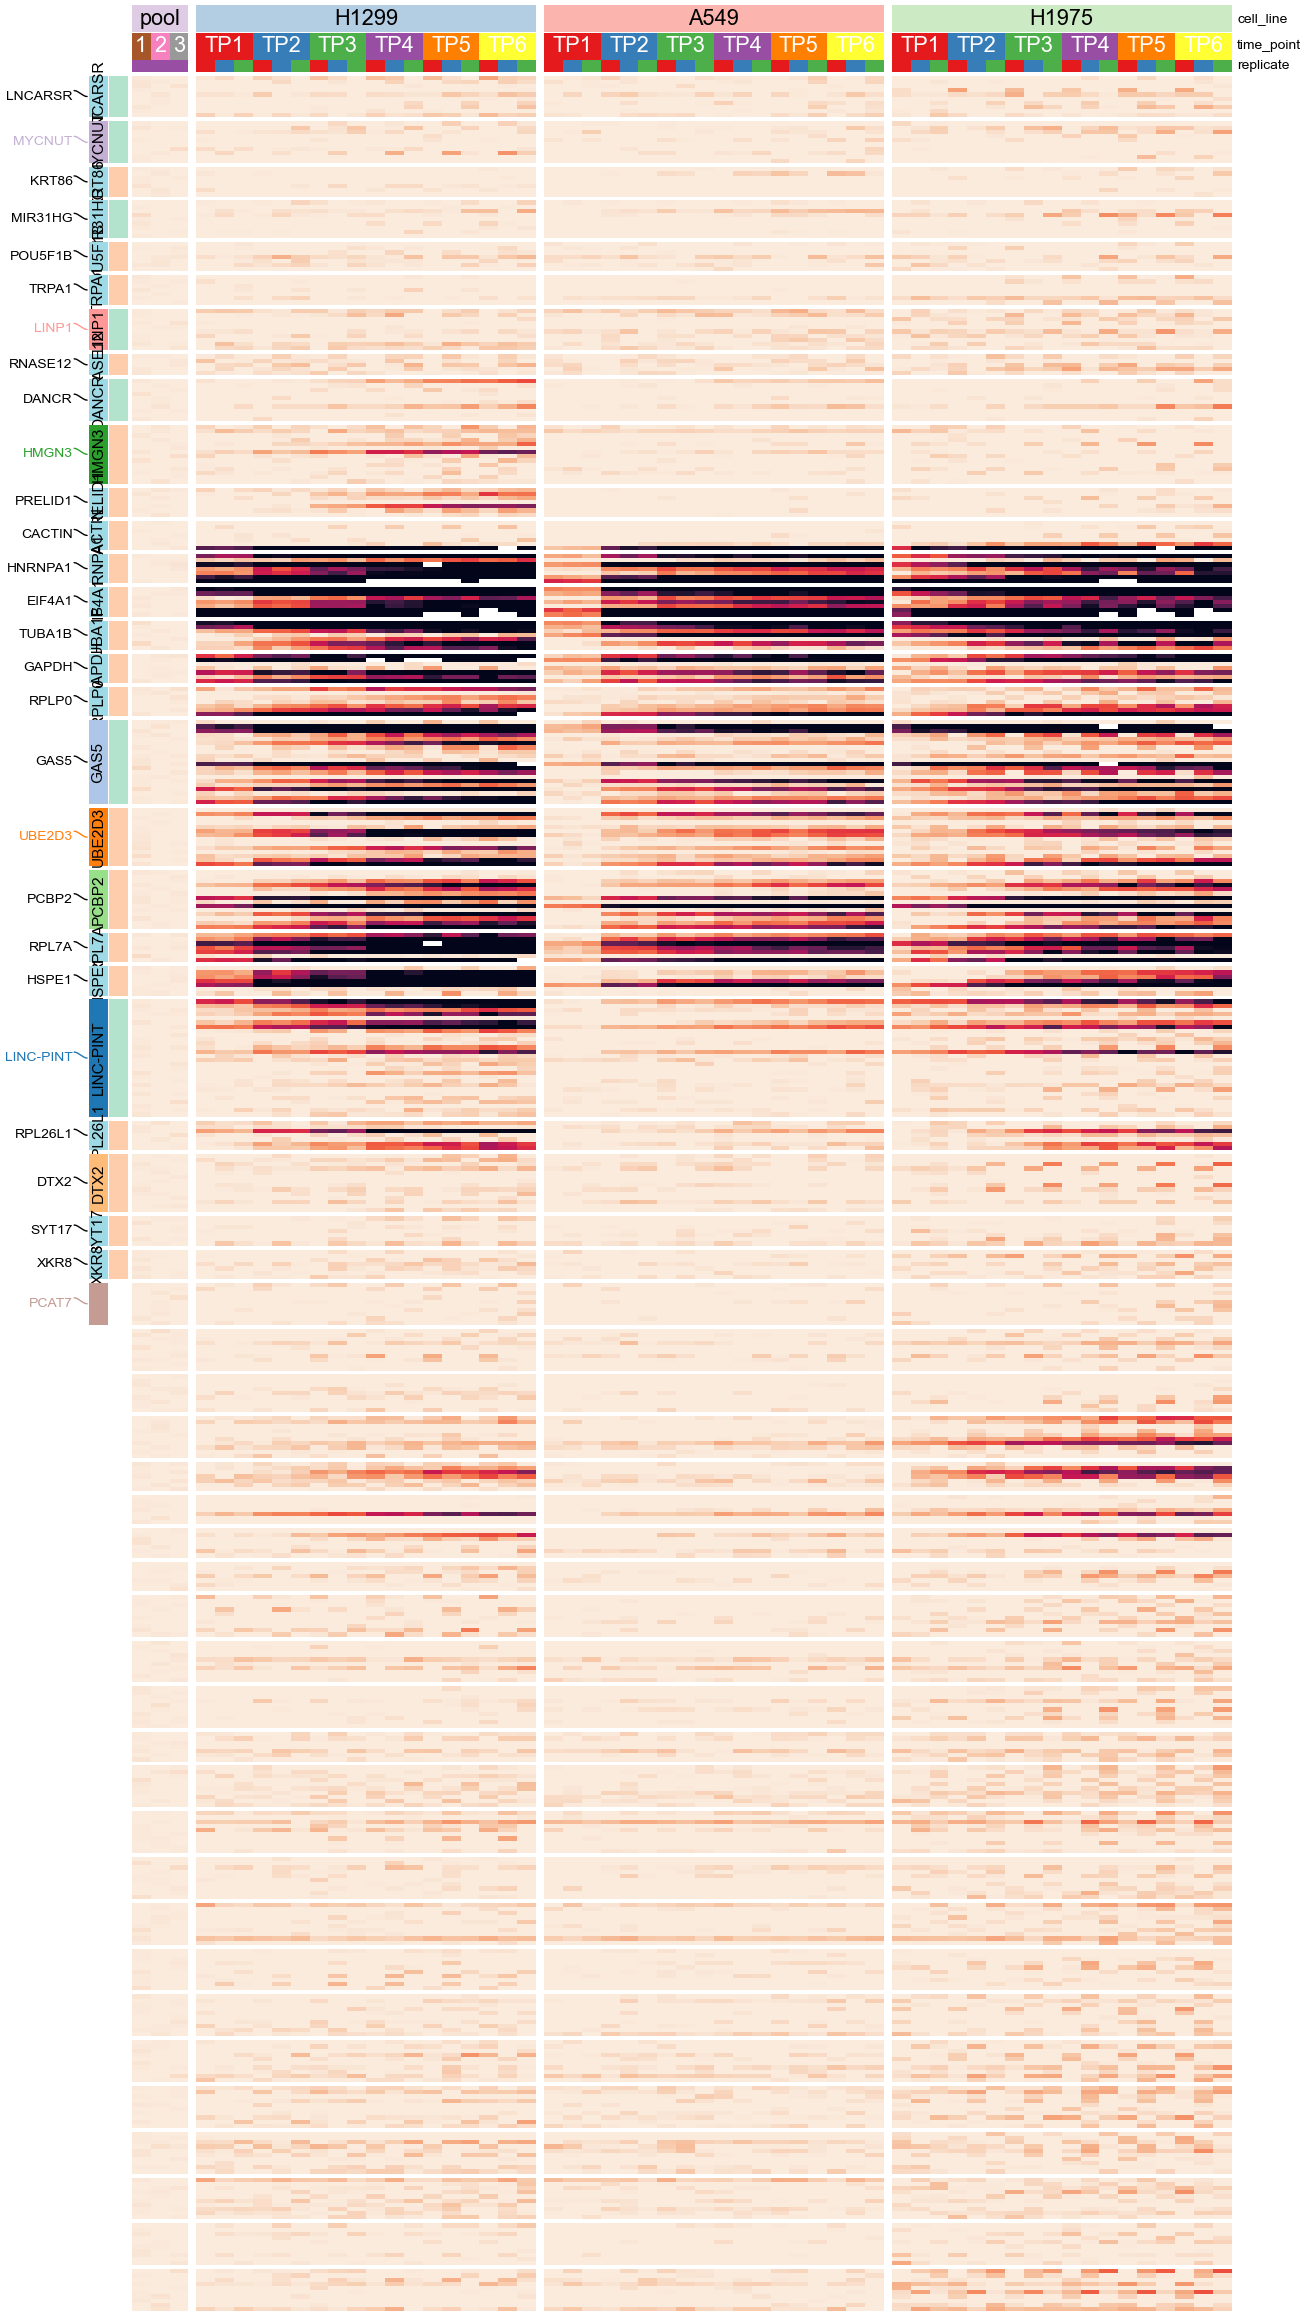

In [13]:
import PyComplexHeatmap as pch
df_sub['mean_l2fc'] = l2fc_sub.mean(axis=1)

# df_sub = df_sub[df.Gene.isin(tops.index)]
# l2fc_sub = l2fc_sub.loc[df.index]

biotype = df_sub.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc_sub.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df_sub.Gene, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df_sub.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    biotype=pch.anno_simple(biotype, legend=True, height=5, add_text=False, cmap='Pastel2'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 30))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df_sub.Gene,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Top 10 Cell line specific genes (via MAGeCK)', y=0.92)
# pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [51]:
# Get the foldchange for the guide targeting genes with variants in guides
# (This also grabs all the other guides that target the same gene but might not have variants)
l2fc_genes = l2fc.index.str.split("_").str[0]
l2fc_sub = l2fc[l2fc_genes.isin(genes_with_variants)]
df_sub = df[df.Gene.isin(genes_with_variants)]

# select only genes with overall higher effect maximum
temp = l2fc_sub.min(axis=1).to_frame().reset_index().rename(columns={0: 'max_l2fc'})
temp['gene'] = temp.unique_guide_name.str.split('_').str[0]
ranking = temp.groupby('gene')['max_l2fc'].min().reset_index().sort_values('max_l2fc', ascending=True)
selected_genes = ranking.gene.unique()[30:40]
len(selected_genes)

10

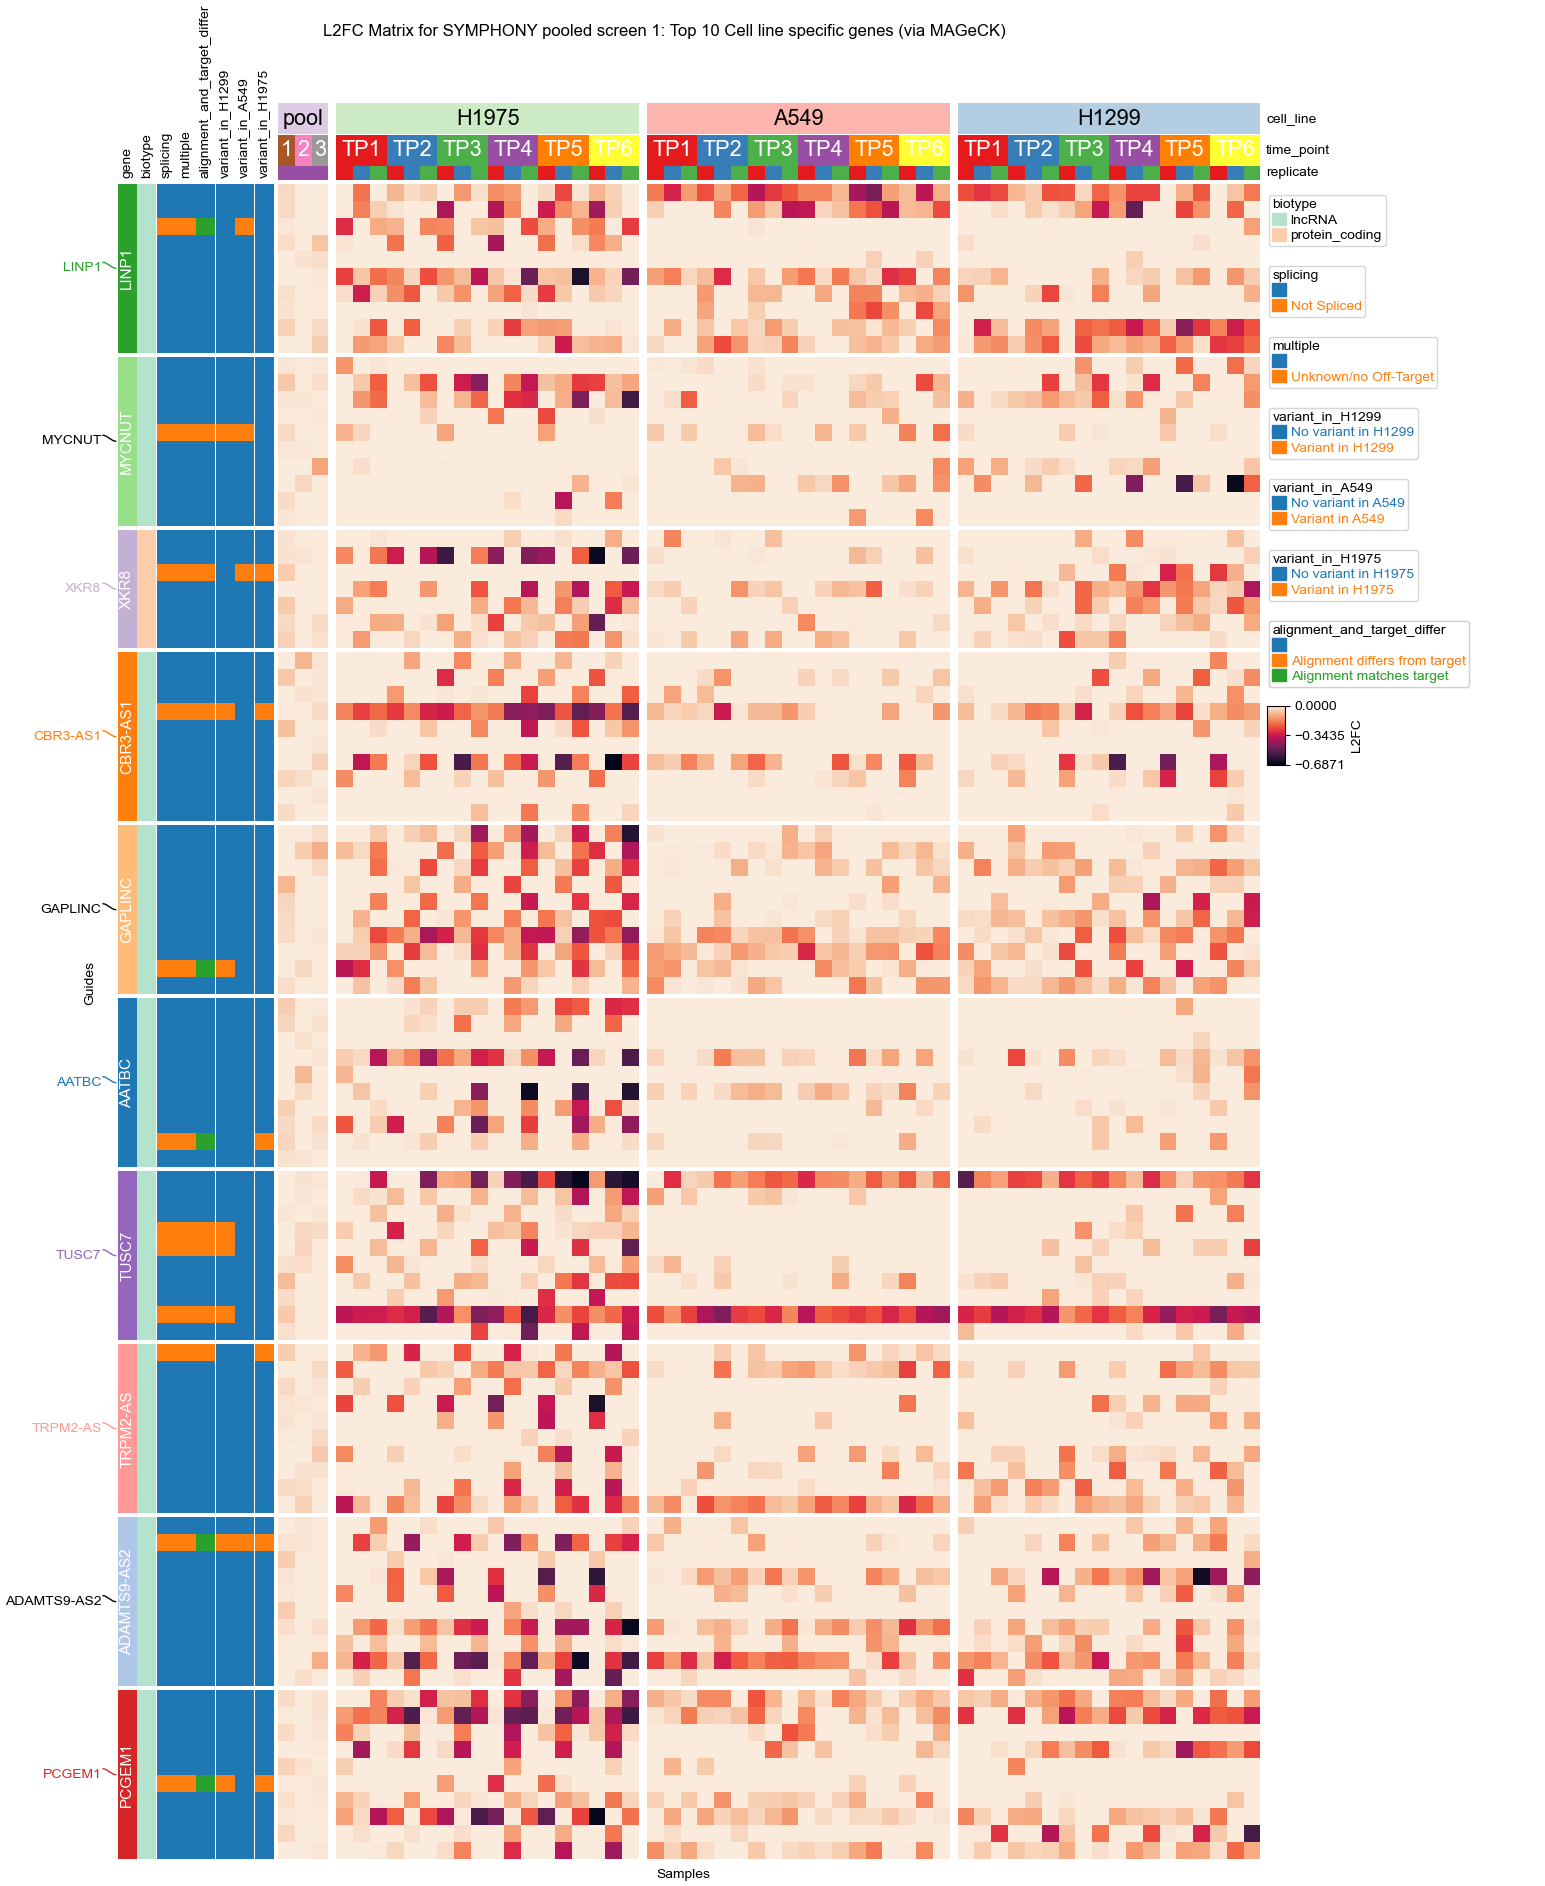

In [52]:
import PyComplexHeatmap as pch
# Get the foldchange for the guide targeting genes with variants in guides
# (This also grabs all the other guides that target the same gene but might not have variants)
l2fc_genes = l2fc.index.str.split("_").str[0]
l2fc_sub = l2fc[l2fc_genes.isin(genes_with_variants)]
df_sub = df[df.Gene.isin(genes_with_variants)]
df_sub = pd.merge(df_sub, subdf.set_index('qname'), left_index=True, right_index=True, how='left')
df_sub['mean_l2fc'] = l2fc_sub.mean(axis=1)
df_sub = df_sub[df.Gene.isin(selected_genes)]
l2fc_sub = l2fc_sub.loc[df_sub.index]

# remove duplicates # TODO;
df_sub = df_sub[~df_sub.index.duplicated(keep='first')]
l2fc_sub = l2fc_sub[~l2fc_sub.index.duplicated(keep='first')]

biotype = df_sub.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc_sub.loc[:, col_order]
biotype = biotype[~data.index.duplicated(keep='first')]
data = data[~data.index.duplicated(keep='first')]
assert len(data) == len(biotype), "Length mismatch"
data = data.loc[biotype.index]
assert all(data.index==biotype.index), "Index mismatch"

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df_sub.Gene, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df_sub.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    biotype=pch.anno_simple(biotype, legend=True, height=5, add_text=False, cmap='Pastel2'),
    
    splicing=pch.anno_simple(df_sub.is_spliced.astype(str).replace({'True': 'Spliced', 'False': 'Not Spliced', 'nan': ''}), legend=True, height=5, add_text=False, cmap='tab10'),
    multiple=pch.anno_simple(df_sub.is_spliced.astype(str).replace({'True': 'Off-Targets', 'False': 'Unknown/no Off-Target', 'nan': ''}), legend=True, height=5, add_text=False, cmap='tab10'),
    alignment_and_target_differ=pch.anno_simple(
        df_sub.alignment_and_target_differ.astype(str).replace({'True': 'Alignment differs from target', 'False': 'Alignment matches target', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    variant_in_H1299=pch.anno_simple(
        df_sub.variant_location_H1299.notna().astype(str).replace({'True': 'Variant in H1299', 'False': 'No variant in H1299', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    variant_in_A549=pch.anno_simple(
        df_sub.variant_location_A549.notna().astype(str).replace({'True': 'Variant in A549', 'False': 'No variant in A549', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    variant_in_H1975=pch.anno_simple(
        df_sub.variant_location_H1975.notna().astype(str).replace({'True': 'Variant in H1975', 'False': 'No variant in H1975', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 20))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, 
    top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df_sub.Gene,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Top 10 Cell line specific genes (via MAGeCK)', y=0.92)
# pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [54]:
# Genes with interesting variants guides
# These are some of the genes with guides that have variants in at least one cell line
goi = ['TUBA1B', 'HNRNPA1', 'RPL7A', 'GAS5', 'HSPE1', 'RPLP0', 'RPL26L1', 'LINC-ROR', 'OVAAL']

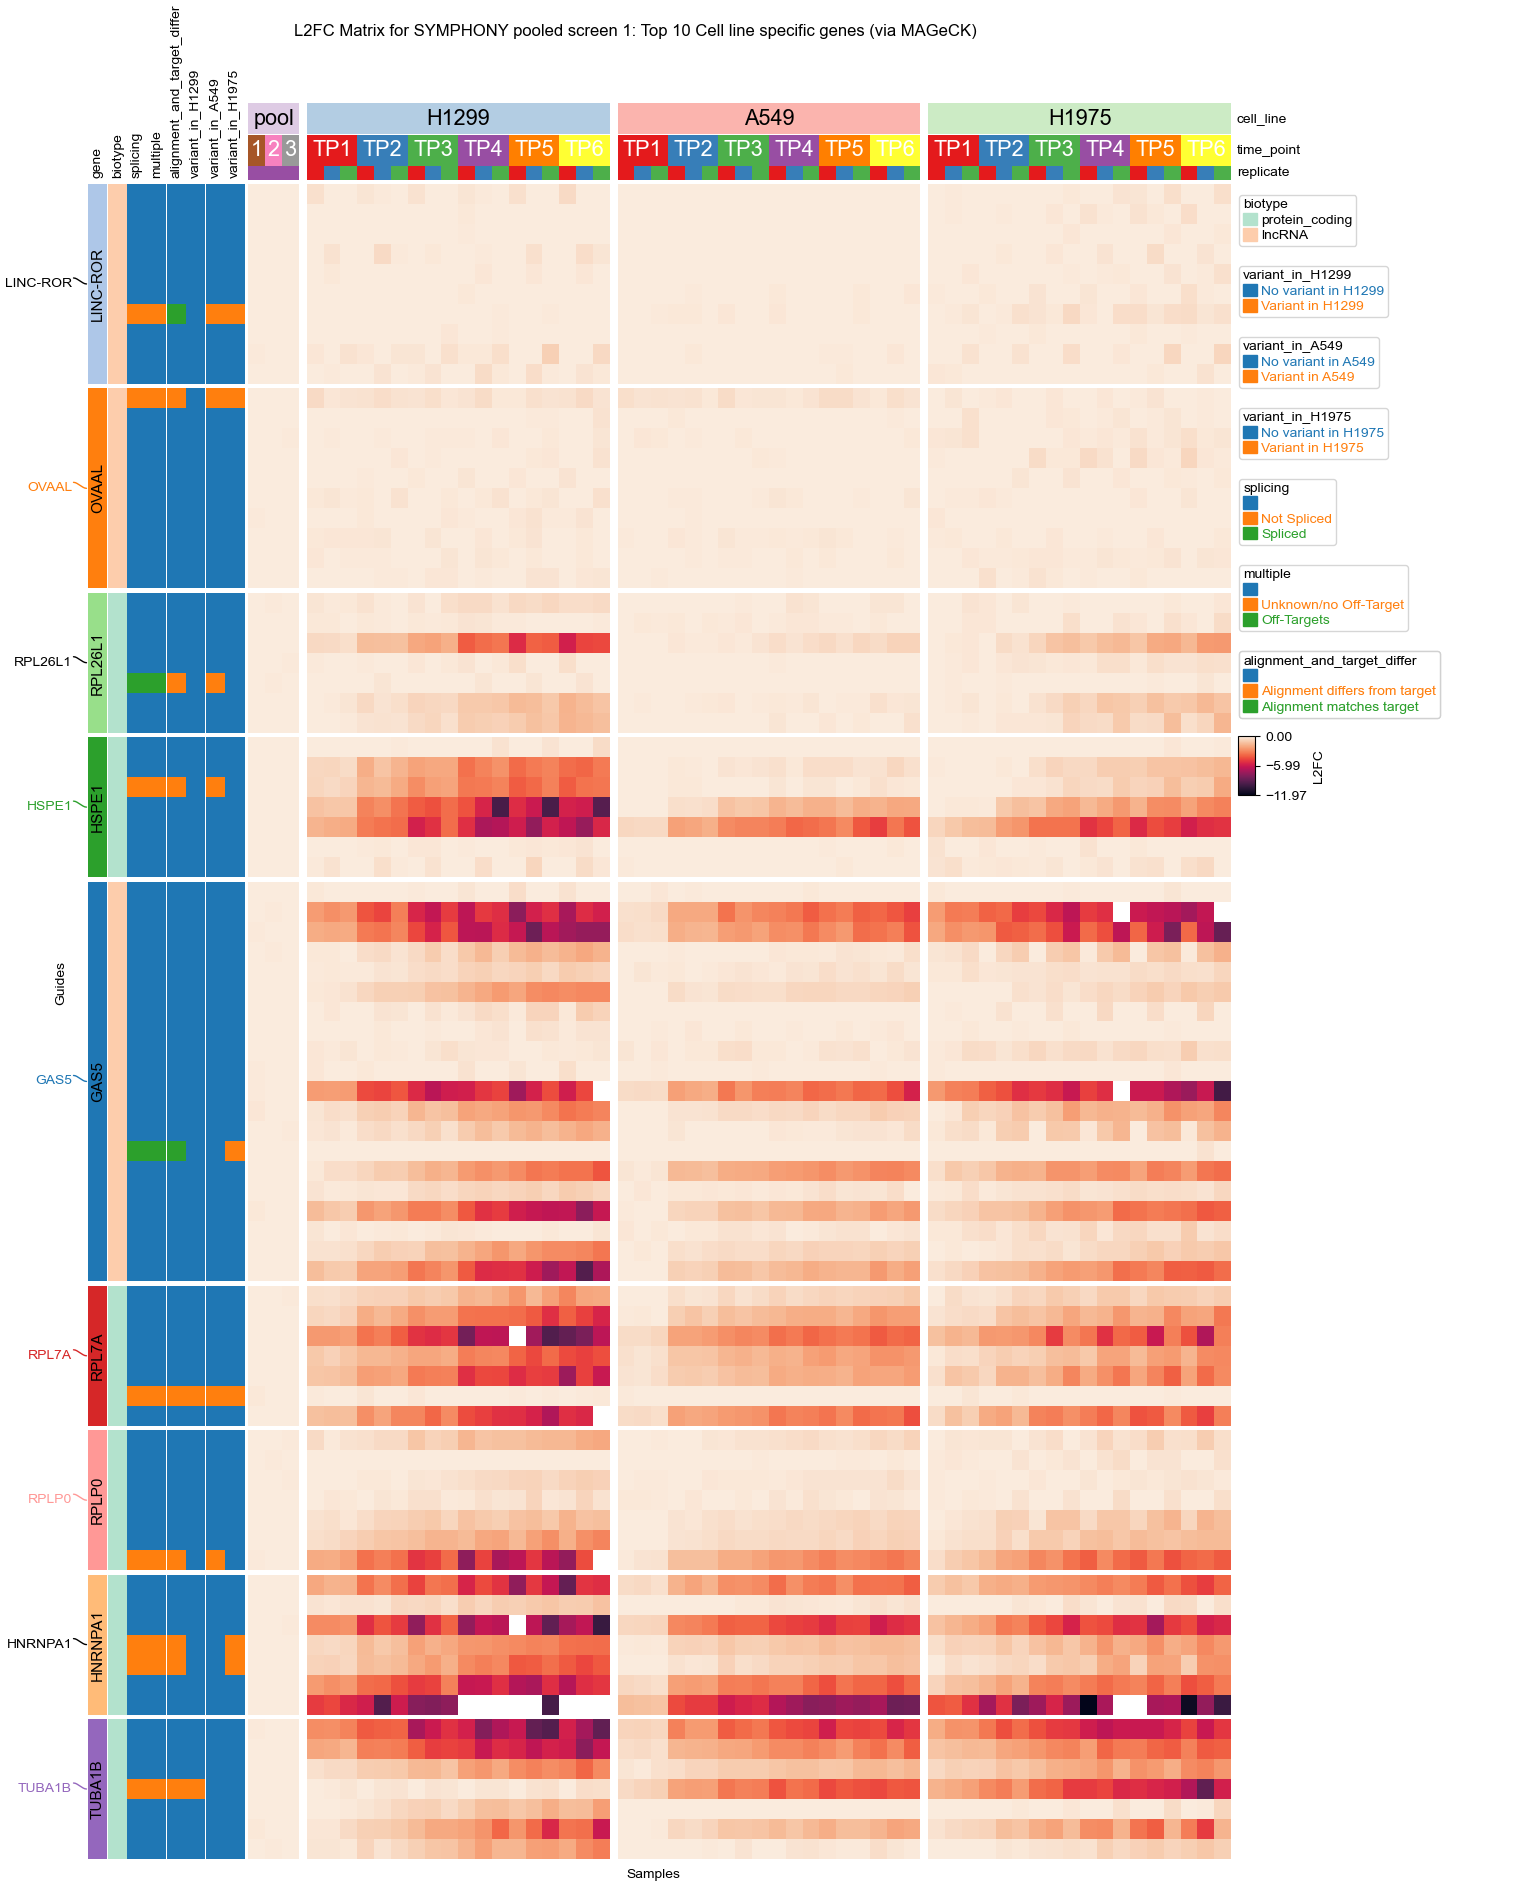

In [55]:
import PyComplexHeatmap as pch
# Get the foldchange for the guide targeting genes with variants in guides
# (This also grabs all the other guides that target the same gene but might not have variants)
l2fc_genes = l2fc.index.str.split("_").str[0]
l2fc_sub = l2fc[l2fc_genes.isin(genes_with_variants)]
df_sub = df[df.Gene.isin(genes_with_variants)]
df_sub = pd.merge(df_sub, subdf.set_index('qname'), left_index=True, right_index=True, how='left')
df_sub['mean_l2fc'] = l2fc_sub.mean(axis=1)
df_sub = df_sub[df.Gene.isin(goi)]
l2fc_sub = l2fc_sub.loc[df_sub.index]

# remove duplicates # TODO;
df_sub = df_sub[~df_sub.index.duplicated(keep='first')]
l2fc_sub = l2fc_sub[~l2fc_sub.index.duplicated(keep='first')]

biotype = df_sub.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc_sub.loc[:, col_order]
biotype = biotype[~data.index.duplicated(keep='first')]
data = data[~data.index.duplicated(keep='first')]
assert len(data) == len(biotype), "Length mismatch"
data = data.loc[biotype.index]
assert all(data.index==biotype.index), "Index mismatch"

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df_sub.Gene, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df_sub.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    biotype=pch.anno_simple(biotype, legend=True, height=5, add_text=False, cmap='Pastel2'),
    
    splicing=pch.anno_simple(df_sub.is_spliced.astype(str).replace({'True': 'Spliced', 'False': 'Not Spliced', 'nan': ''}), legend=True, height=5, add_text=False, cmap='tab10'),
    multiple=pch.anno_simple(df_sub.is_spliced.astype(str).replace({'True': 'Off-Targets', 'False': 'Unknown/no Off-Target', 'nan': ''}), legend=True, height=5, add_text=False, cmap='tab10'),
    alignment_and_target_differ=pch.anno_simple(
        df_sub.alignment_and_target_differ.astype(str).replace({'True': 'Alignment differs from target', 'False': 'Alignment matches target', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    variant_in_H1299=pch.anno_simple(
        df_sub.variant_location_H1299.notna().astype(str).replace({'True': 'Variant in H1299', 'False': 'No variant in H1299', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    variant_in_A549=pch.anno_simple(
        df_sub.variant_location_A549.notna().astype(str).replace({'True': 'Variant in A549', 'False': 'No variant in A549', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    variant_in_H1975=pch.anno_simple(
        df_sub.variant_location_H1975.notna().astype(str).replace({'True': 'Variant in H1975', 'False': 'No variant in H1975', 'nan': ''}),
        legend=True, height=5, add_text=False, cmap='tab10'
    ),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 20))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, 
    top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df_sub.Gene,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Top 10 Cell line specific genes (via MAGeCK)', y=0.92)
# pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [37]:
df_sub.is_spliced.astype(str).replace({'True': 'Spliced', 'False': 'Not Spliced', 'nan': ''}).value_counts()

is_spliced
               85
Not Spliced    11
Spliced         1
Name: count, dtype: int64

In [32]:
df_sub

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments,variant_location_H1975,variant_location_H1299,variant_location_A549,mean_l2fc
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
CACTIN_ENST00000429344_1264,ENST00000429344,ENSG00000105298,CACTIN,protein_coding,crRNA1212:1242-1264,GACTGCACATCAGAGCTGACGGA,1264.0,1.021592,CDS,3583.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.273442
CACTIN_ENST00000429344_26,ENST00000429344,ENSG00000105298,CACTIN,protein_coding,crRNA0004:4-26,CACCAATAGCCGAAGCCTGCGCT,26.0,0.876230,UTR5,3583.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.142662
CACTIN_ENST00000429344_30,ENST00000429344,ENSG00000105298,CACTIN,protein_coding,crRNA0008:8-30,CCAACACCAATAGCCGAAGCCTG,30.0,1.080028,UTR5,3583.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.190848
CACTIN_ENST00000429344_3063,ENST00000429344,ENSG00000105298,CACTIN,protein_coding,crRNA2981:3041-3063,ACCTTGACAGAGACAGGGACCTC,3063.0,1.003335,UTR3,3583.0,...,False,Not junctional,CACTIN;CACTIN-AS1,CACTIN,True,True,NaN,3611192.0,3611192.0,0.070082
CACTIN_ENST00000429344_3069,ENST00000429344,ENSG00000105298,CACTIN,protein_coding,crRNA2987:3047-3069,CCCACGACCTTGACAGAGACAGG,3069.0,0.984189,UTR3,3583.0,...,False,Not junctional,CACTIN;CACTIN-AS1,CACTIN,True,True,NaN,3611188.0,3611188.0,0.185793
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UBE2D3_ENST00000394803_505,ENST00000394803,ENSG00000109332,UBE2D3,protein_coding,crRNA0483:483-505,ATTGTCAAAAAGAATACACCGCC,505.0,1.485616,CDS,2227.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.322885
GAS5_ENST00000448718_436,ENST00000448718,ENSG00000234741,GAS5,lncRNA,crRNA414:414-436,GTAAGCTTCAAAGGCCACTGCAC,436.0,0.853030,Gene_Body,592.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.473378
CACTIN_ENST00000429344_2051,ENST00000429344,ENSG00000105298,CACTIN,protein_coding,crRNA1987:2029-2051,GTCAAAGTCGTAGTGCGTCTGGT,2051.0,1.032726,CDS,3583.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4.375617


In [33]:
df_sub.columns

Index(['Transcript_ID', 'ensembl_gene_id', 'Gene', 'transcript_biotype',
       'GuideName', 'GuideSeq', 'MatchPos', 'Guide_Score', 'Region',
       'transcript_length', 'gRNA_occurence', 'transcript_per_gene',
       'Sym-pool-1-1', 'Sym-pool-1-2', 'Sym-pool-1-3', 'sym-01-01-TP1',
       'sym-01-01-TP2', 'sym-01-01-TP3', 'sym-01-01-TP4', 'sym-01-01-TP5',
       'sym-01-02-TP6', 'sym-01-02-TP1', 'sym-01-02-TP2', 'sym-01-02-TP3',
       'sym-01-02-TP4', 'sym-01-02-TP5', 'sym-01-01-TP6', 'sym-01-03-TP1',
       'sym-01-03-TP2', 'sym-01-03-TP3', 'sym-01-03-TP4', 'sym-01-03-TP5',
       'sym-01-03-TP6', 'sym-02-01-TP1', 'sym-02-01-TP2', 'sym-02-01-TP3',
       'sym-02-01-TP4', 'sym-02-01-TP5', 'sym-02-01-TP6', 'sym-02-02-TP1',
       'sym-02-02-TP2', 'sym-02-02-TP3', 'sym-02-02-TP4', 'sym-02-02-TP5',
       'sym-02-02-TP6', 'sym-02-03-TP1', 'sym-02-03-TP2', 'sym-02-03-TP3',
       'sym-02-03-TP4', 'sym-02-03-TP5', 'sym-02-03-TP6', 'sym-03-01-TP1',
       'sym-03-01-TP2', 'sym-03-01-TP3', '

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
CACTIN_ENST00000429344_1264,0.006738,-0.032745,0.025398,0.415830,0.326874,0.371121,0.278398,0.299552,0.339326,0.145719,...,0.422640,0.389768,0.374052,0.291297,0.443577,0.393096,0.362720,0.341862,0.352510,0.290628
CACTIN_ENST00000429344_26,0.010899,0.000260,-0.011243,-0.138879,0.389606,0.321674,0.364294,-0.014285,-0.172608,0.262631,...,0.364709,0.343418,0.149483,0.106913,0.282619,0.376637,0.235838,0.369803,0.244839,0.064485
CACTIN_ENST00000429344_30,-0.032968,0.000830,0.031420,0.475246,0.373320,0.499375,0.473571,0.347000,0.314814,-0.005951,...,0.103456,0.085301,0.077741,0.132079,0.110044,0.091031,0.118854,0.193232,0.127584,-0.051553
CACTIN_ENST00000429344_3063,0.021892,-0.010357,-0.011787,0.299596,0.144002,0.163211,0.182369,0.401128,0.282734,0.157042,...,0.109974,0.145601,-0.022087,0.034553,0.168145,0.209246,0.207018,0.114002,0.132441,0.121955
CACTIN_ENST00000429344_3069,0.011163,-0.018641,0.007296,0.215637,0.203094,0.246072,0.208600,0.219430,-0.029687,0.290647,...,0.175234,0.110346,0.291072,0.016209,0.235272,0.204331,0.279223,0.063128,0.236803,0.010380
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UBE2D3_ENST00000394803_505,-0.066404,0.059162,0.004500,-0.459466,-0.730489,-1.509443,-2.475253,-2.745666,-2.935964,-0.721720,...,-1.326255,-1.674849,-1.534999,-2.452398,-0.106491,-0.813328,-1.208308,-2.195489,-1.894239,-2.862926
GAS5_ENST00000448718_436,-0.030132,0.052167,-0.023492,-0.347815,-1.268940,-1.803114,-2.325304,-3.340403,-3.986549,-0.578171,...,-1.414360,-1.597800,-1.667069,-1.927158,0.207755,-0.850156,-1.123051,-1.935963,-1.679020,-2.335216
CACTIN_ENST00000429344_2051,0.038780,-0.001591,-0.038218,-1.346552,-2.470665,-3.497419,-3.525142,-3.782991,-3.303095,-3.195739,...,-3.890677,-3.903030,-3.934244,-4.193183,-0.414990,-2.573911,-3.530238,-4.325757,-4.966247,-5.059940


In [228]:
data.shape

(139, 57)

In [232]:
'GAS5_ENST00000450589_376' in df_sub.Gene

True

In [227]:
biotype

unique_guide_name
CACTIN_ENST00000429344_1264     protein_coding
CACTIN_ENST00000429344_26       protein_coding
CACTIN_ENST00000429344_30       protein_coding
CACTIN_ENST00000429344_3063     protein_coding
CACTIN_ENST00000429344_3069     protein_coding
                                     ...      
UBE2D3_ENST00000394803_505      protein_coding
GAS5_ENST00000448718_436                lncRNA
CACTIN_ENST00000429344_2051     protein_coding
EIF4A1_ENST00000293831_793      protein_coding
HNRNPA1_ENST00000330752_1264    protein_coding
Name: transcript_biotype, Length: 142, dtype: object